# PW7 - Encoding, System Design and Debugging

**Team:** Noé Berdoz, Michael Strefeler

Our starting levels, the time spent per exercise and the bonus request are in the preamble of `ex1-analysis.ipynb`.

# Exercise 3 - Linear regression optimisation

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from numpy.linalg import pinv

a) Read the data in separate variables for the training and test sets.

In [2]:
dataset_train = pd.read_csv('overfitting_train.csv')
dataset_test = pd.read_csv('overfitting_test.csv')

In [3]:
dataset_train.head()

,x,y
0,-1.000000,-1.859783
1,0.333333,2.768337
2,1.666667,3.246021
3,3.000000,1.784168
4,4.333333,2.175140


In [4]:
X_train = dataset_train['x'].values
y_train = dataset_train['y'].values
X_test = dataset_test['x'].values
y_test = dataset_test['y'].values

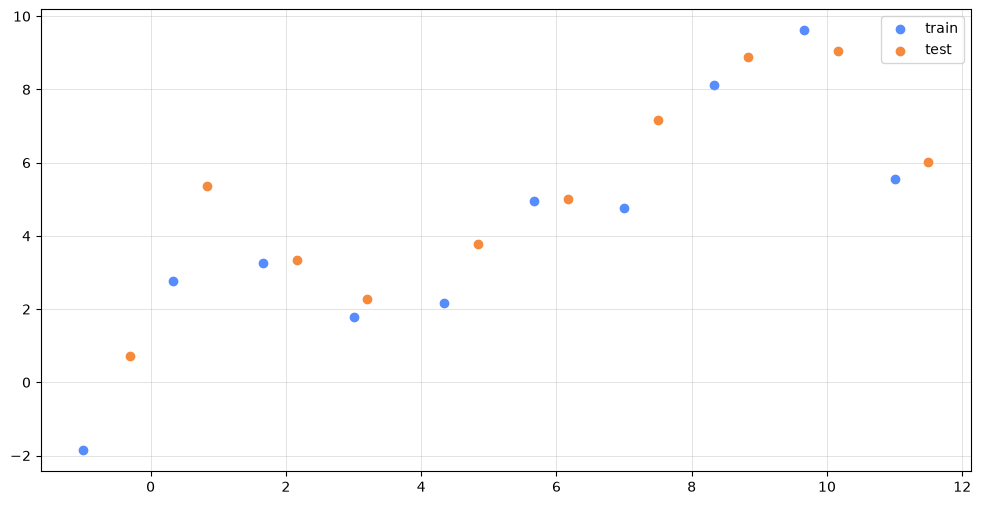

In [5]:
plt.figure(figsize=(12,6))
plt.grid(alpha=0.5)
plt.scatter(X_train, y_train)
plt.scatter(X_test, y_test)
plt.legend(['train', 'test']);

b) Define a cost function
$J(θ)$
that will allow you to compute the cost on the training and
cross-validation sets.


$$J(\theta) = \frac{1}{2N} \sum_{n=1}^{N} (h_{\theta}(\mathbf{x}_{n}) - y_{n})^{2}$$

where $h_{\theta}(\mathbf{x}_{n})$ is your prediction.

In [6]:
def compute_cost(y_pred, y_true):
    N = y_pred.shape[0]
    return (1.0 / (2.0 * N)) * np.sum((y_pred - y_true)**2)

c) Perform the training for increasing orders $O= 1 ,..., 10$.

You can use any training method developed in the previous practical work. Using the [normal equation](http://mlwiki.org/index.php/Normal_Equation) is probably the easiest choice.

In [9]:
# TODO: implement the training method. The pseudo-code here is mostly for the normal equation. Adapt to your needs. -> DONE

# rescale x to [-1, 1] with the training min and max, so that the powers of x keep similar sizes
x_min = X_train.min()
x_max = X_train.max()

def scale(X):
    return 2 * (X - x_min) / (x_max - x_min) - 1

def make_design(X, order):
    columns = []
    for p in range(order + 1):
        columns.append(X**p)
    return np.column_stack(columns)

def fit(X_train: np.array, y_train: np.array, order: float) -> np.array:
    X_design = make_design(scale(X_train), order)
    thetas = pinv(X_design.T.dot(X_design)).dot(X_design.T).dot(y_train)
    return thetas

def predict(thetas: np.array, X: np.array) -> np.array:
    y_pred = 0
    for p in range(len(thetas)):
        y_pred = y_pred + thetas[p] * scale(X)**p
    return y_pred

Order=1; cost on train set: 1.41; cost on test set: 1.68
Order=2; cost on train set: 1.35; cost on test set: 1.61
Order=3; cost on train set: 1.31; cost on test set: 1.54
Order=4; cost on train set: 0.20; cost on test set: 1.03
Order=5; cost on train set: 0.20; cost on test set: 0.98
Order=6; cost on train set: 0.14; cost on test set: 2.19
Order=7; cost on train set: 0.11; cost on test set: 4.39
Order=8; cost on train set: 0.05; cost on test set: 1.52
Order=9; cost on train set: 0.00; cost on test set: 137.78
Order=10; cost on train set: 0.00; cost on test set: 192.40


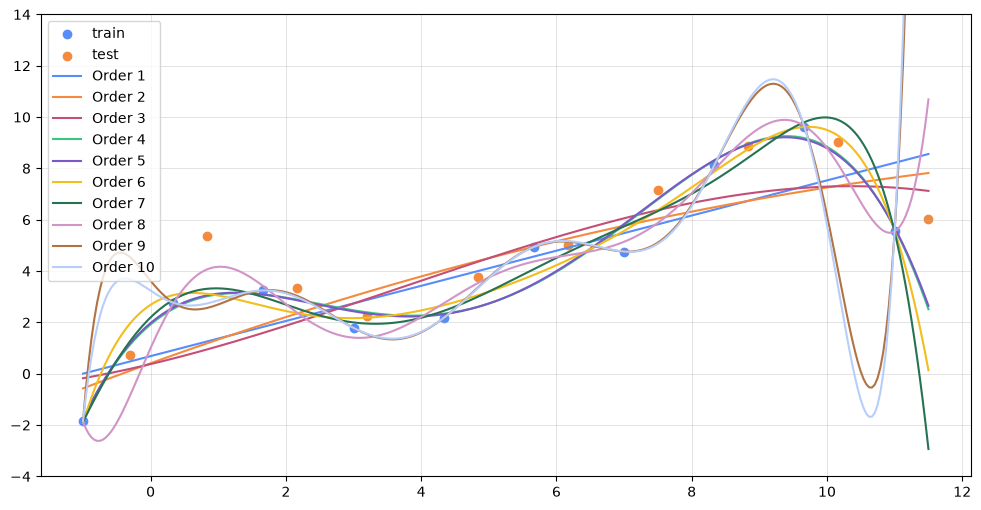

In [16]:
plt.figure(figsize=(12,6))
plt.grid(alpha=0.5)
plt.scatter(X_train, y_train)
plt.scatter(X_test, y_test)

x_plot = np.linspace(-1, 11.5, 300)
orders = list(range(1, 11))

train_cost_curve = []
test_cost_curve = []
for order in orders:
    thetas = fit(X_train, y_train, order)
    plt.plot(x_plot, predict(thetas, x_plot))
    
    # Test on train set
    cost_train = compute_cost(predict(thetas, X_train), y_train)
    train_cost_curve.append(cost_train)
    
    # Test on test set
    cost_test = compute_cost(predict(thetas, X_test), y_test)
    test_cost_curve.append(cost_test)

    print(f"Order={order}; cost on train set: {cost_train:.2f}; cost on test set: {cost_test:.2f}")


plt.ylim(-4, 14)  # zoom on the data, high orders explode
plt.legend(['train', 'test'] + [f"Order {i}" for i in orders]); # labels in drawing order

e) Plot the evolution of the costs
$J_{train}(θ)$ and $J_{cv}(θ)$
as a function of the order O.

lowest test cost at order 5


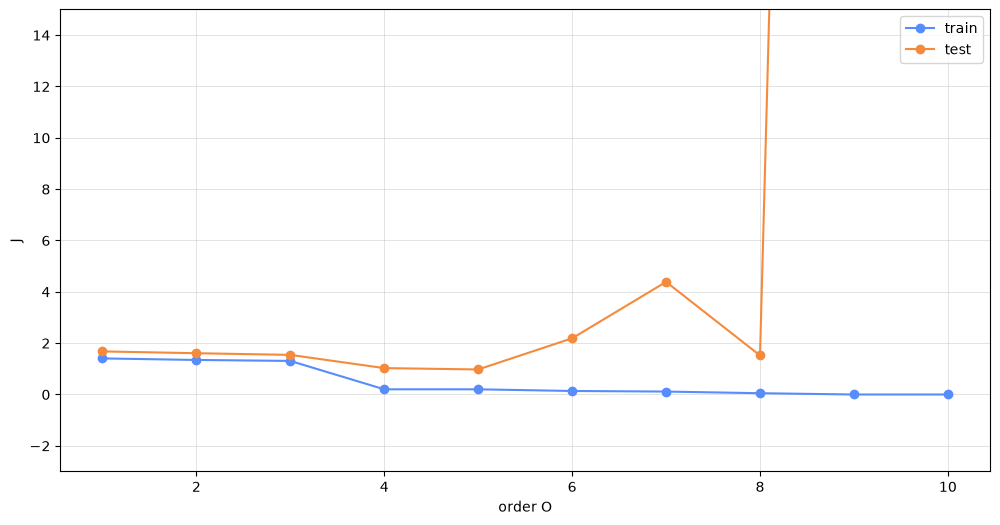

In [17]:
plt.figure(figsize=(12,6))
plt.grid(alpha=0.5)
plt.plot(orders, train_cost_curve, 'o-')  # x axis = the real orders 1 to 10
plt.plot(orders, test_cost_curve, 'o-')
plt.xlabel('order O')
plt.ylabel('J')
plt.ylim(-3, 15)
plt.legend(['train', 'test']);

print('lowest test cost at order', orders[np.argmin(test_cost_curve)])

# TODO: or adapt to your own method of costs computation -> DONE

**f) What is your best model according to these costs ? Comment your answer.**

In [19]:
# J_train of orders 4 and 5 with 4 decimals, to compare them more precisely
i4 = orders.index(4)
i5 = orders.index(5)
print(f"J_train: order 4 = {train_cost_curve[i4]:.4f}, order 5 = {train_cost_curve[i5]:.4f}")

# at order 5, how much of the test error comes from the point furthest to the right?
thetas_5 = fit(X_train, y_train, 5)
errors = (predict(thetas_5, X_test) - y_test)**2
last = np.argmax(X_test)
print('test point x =', X_test[last], '-> share of the error sum:', round(errors[last] / np.sum(errors), 2))

J_train: order 4 = 0.2023, order 5 = 0.2018
test point x = 11.5 -> share of the error sum: 0.58


According to these costs, the best model is O = 5, with the lowest J_cv = 0.98. O = 4 is very close with 1.03, and both have almost the same J_train at 0.20 (0.2023 and 0.2018 when checked with 4 decimals), so the fifth power adds almost nothing. The lowest J_train, 0 at O = 9 and 10, does not point to a good model. These polynomials go through every training point and miss the test points, with J_cv above 137. At O = 5, the single test point x = 11.5, outside the training range, makes 58% of the error sum.

**g) Would you still choose the model with the lowest cost for production?**

TODO: answer

**h) Explain how under/over-fitting is involved here.**

TODO: answer